# ✈️ TravelTide – Part 3: Segments, Models & Perks

**Masterschool (MSIT) Data Analytics – Mastery Project**

Part 2 built one row per user with behavioral features. This notebook turns them into **customer segments** and matches each segment to one of Elena's five perks.

1. Rule-based segments – transparent rules in a fixed priority order
2. Habit or luck? – each rule tested against chance, which tells us how strongly the data supports each of Elena's perks
3. Perk mapping – one core perk per segment, plus a pilot perk; perk scores for customers without a dominant habit
4. K-Means – a data-driven check: does the algorithm find the same groups without being told the rules?
5. Final perk for every customer – segments plus perk scores for the All-rounders → `user_perks.csv`
6. DBSCAN – a density-based second check: which groups are truly separate, and who are the outliers?
7. PCA – can fewer dimensions simplify the picture? (plus a 2-D map of all bookers)
8. Personas – one typical customer per segment, for the presentation

## 1 – Setup & Data Loading

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy.stats import binom
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score

pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")
PALETTE = ["#3D90F3", "#A9CCF5", "#2E7D8C", "#1B4F8A", "#0D0F14", "#79B7F6"]
sns.set_palette(PALETTE)

# Theme gradient for charts with several groups (pale green-blue → TravelTide blue → navy)
from matplotlib.colors import LinearSegmentedColormap
TT_CMAP = LinearSegmentedColormap.from_list("traveltide", ["#DDF1E4", "#A8DDB5", "#4EB3D3", "#3D90F3", "#1B4F8A"])
def theme_shades(n):
    """n colors along the theme gradient – one shade per group, light to dark."""
    return [TT_CMAP(x) for x in np.linspace(0.15, 1, n)]

# Same data folder logic as Parts 1 and 2: repo root, notebooks/ subfolder or Colab with Drive mounted
CANDIDATE_DIRS = [Path("data"), Path("../data"), Path("/content/drive/MyDrive/DS Mastery Project/data")]
DATA_DIR = next((d for d in CANDIDATE_DIRS if d.is_dir()), Path("data"))   # no folder yet → create data/ here
DATA_DIR.mkdir(exist_ok=True)
print("Data folder:", DATA_DIR.resolve())

# Google Drive backup (shared as "Anyone with the link – Viewer"), only used if a file is missing locally
DRIVE_IDS = {"users_features.csv": "1UwGBmqvTmds8_YLr4vMrrMMavQd5MkHG",
             "sessions_clean.csv": "1yvU9EUJkj92d_7y7-uLdbZY252Brkl8B"}   # trip level, only for the habit check (section 3)

def load_csv(name, **kwargs):   # Load a CSV file from the local data folder or Google Drive backup if missing
    if (DATA_DIR / name).exists():
        print(f"{name}: read from local folder")
        return pd.read_csv(DATA_DIR / name, **kwargs)
    if not DRIVE_IDS.get(name):
        raise FileNotFoundError(f"{name} is not in {DATA_DIR.resolve()} – run notebook 02 first (it creates this file).")
    print(f"{name}: not in the local folder → read from the Google Drive backup")
    return pd.read_csv(f"https://drive.google.com/uc?export=download&id={DRIVE_IDS[name]}", **kwargs)

users = load_csv("users_features.csv").set_index("user_id")
sessions = load_csv("sessions_clean.csv", low_memory=False)
print(f"Users: {len(users):,} | features: {users.shape[1]} | sessions: {len(sessions):,}")

Data folder: C:\Users\jackl\OneDrive\Attachments\Desktop\Masterschool\Mastery Project\TravelTide\data
users_features.csv: read from local folder
sessions_clean.csv: read from local folder
Users: 5,998 | features: 35 | sessions: 49,211


## 2 – Rule-based segments

Each segment is defined by **one clear behavioral marker** found in Part 1. A user can match several rules (e.g. a family that also flies long-haul), so the rules are applied in a **priority order**: the first matching rule wins, and everyone who matches no rule becomes an *All-rounder* – they get their perk from perk scores (4.1).

| # | Segment | Rule | Evidence (Part 1) |
|---|---|---|---|
| 1 | Dreamers | no valid trip | 9 % never kept a booking (5.1, 5.2.3) |
| 2 | Family Crew | has children **and** party size ≥ 1.5 | children alone ≠ family travel (5.3.1) |
| 3 | Couples & Friends | no children **and** party size ≥ 1.5 | seats ≈ rooms (5.5.4) |
| 4 | Hotel Stayers | ≥ 50 % hotel-only trips | hotel-only stays twice as long (5.4.3) |
| 5 | Favourite-City Returners | same city at least twice | 805 repeat-city users (4.2) |
| 6 | Deal Hunters | ≥ 50 % of trips discounted **and** ≥ 2 trips | 23 % of bookings discounted – counting only discounts on the booked part (4.1, 5.5.2) |
| 7 | Long-haul Travellers | ≥ 3,000 km on average | long tail of long-haul flights (5.3.2) |
| 8 | Package Travellers | **every** trip is flight + hotel **and** ≥ 3 trips | packages are 74.7 % of all trips (Part 2, section 4) – booking *only* packages is a habit (section 3) |
| – | All-rounders | everyone else | – |

**Why this order:** the most specific and least frequent markers come first, so they are not absorbed by broad rules; Long-haul Travellers and Package Travellers come last: flying far and booking flight + hotel together are common in every other segment (e.g. groups), so the other markers are more specific.

*A planned 8th segment, **Weekend Escapers** (≥ 50 % Fri/Sat starts and ≤ 3 nights), was tested and dropped – weekend travel turned out to be pure chance (section 3.2). Long-haul Travellers are defined by distance only – checked bags turned out to be luck (section 3.3).*

**Why a 50% Threshold?**

Using 50% ("at least half of their trips") marks a clear habit rather than a one-off event, making the resulting segments intuitive to explain. 

It also fits the data (Part 2, `describe()` table in section 3):
* **Discount share:** 0.5 lies just above the 75th percentile (0.4), isolating the top 23.5% of bookers (Part 2, section 4). For the dropped weekend share, 0.5 is exactly the 75th percentile (30.9%).
* **Hotel-only share:** These trips are rarer (the 75th percentile is 0.33), so 0.5 is an even stricter threshold here, selecting 17.5% of bookers.

Ultimately, 0.5 acts as the natural dividing line between "sometimes" and "mostly."

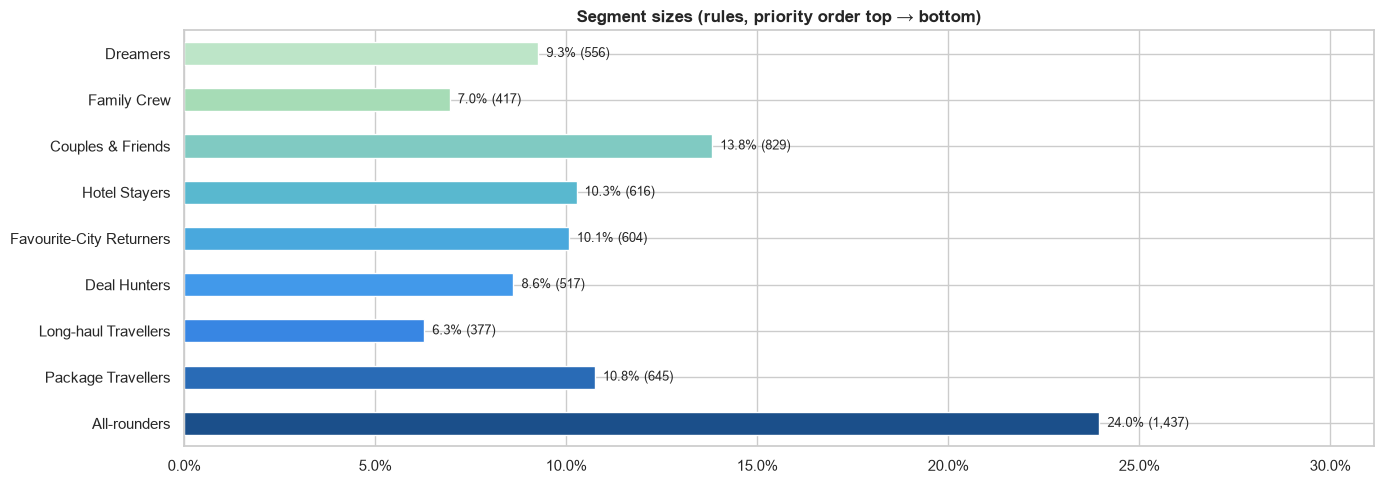

Smallest segment: 6.3 % → every segment ≥ 5 %


In [2]:
RULES = {
    "Dreamers":                 users["is_dreamer"], 
    "Family Crew":              users["has_children"] & (users["party_size"] >= 1.5), # children at home alone don't mean family travel – party size shows they travel together
    "Couples & Friends":        ~users["has_children"] & (users["party_size"] >= 1.5), # party size = larger of avg seats/rooms (r = 0.98, Part 1, 5.5.4)
    "Hotel Stayers":            users["hotel_only_share"] >= 0.5, # hotel-only bookers are a distinct segment with hotel-only stays being twice as long (Part 1, 5.4.3)
    "Favourite-City Returners": users["max_visits_same_city"] >= 2, # same city (flight destination or hotel city) at least twice
    "Deal Hunters":             (users["discount_share"] >= 0.5) & (users["valid_trips"] >= 2), # users with only 1 trip are not necessarily deal hunters, even if they booked a discounted trip
    "Long-haul Travellers":     users["avg_distance_km"] >= 3000, # distance is a habit (section 3); bags alone are luck and don't rise with distance (3.3)
    "Package Travellers":       (users["combo_share"] == 1) & (users["valid_trips"] >= 3), # always flight + hotel together; 3+ trips so it is a habit, not a coincidence (section 3)
}
# missing values (e.g. no hotel stays → no avg_nights) count as "rule not met"
rule_flags = pd.DataFrame({name: mask.fillna(False).astype(bool) for name, mask in RULES.items()})

# first matching rule wins
users["segment"] = "All-rounders"
for name in reversed(RULES):                    # reversed: higher-priority rules overwrite lower ones
    users.loc[rule_flags[name], "segment"] = name

SEGMENT_ORDER = list(RULES) + ["All-rounders"]
SEGMENT_COLORS = dict(zip(SEGMENT_ORDER, theme_shades(len(SEGMENT_ORDER))))   # one shade per segment, reused below
sizes = users["segment"].value_counts().reindex(SEGMENT_ORDER)
fig, ax = plt.subplots(figsize=(14, 5))
shares = sizes / sizes.sum() * 100
shares.plot(kind="barh", ax=ax, color=[SEGMENT_COLORS[s] for s in shares.index])
for i, (s, n) in enumerate(zip(shares, sizes)):
    ax.text(s, i, f"  {s:.1f}% ({n:,})", va="center", fontsize=9)
ax.invert_yaxis(); ax.set_xlim(0, shares.max() * 1.3); ax.xaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title("Segment sizes (rules, priority order top → bottom)", fontweight="bold"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()
print("Smallest segment:", f"{shares.min():.1f} %", "→ every segment ≥ 5 %" if shares.min() >= 5 else "→ below 5 %, adjust a threshold")

### 2.1 How often do the rules overlap?
The heatmap counts users who meet **two rules at once** (before the priority order). Large overlaps show where the order decides the segment – and justify putting the narrow rules first.

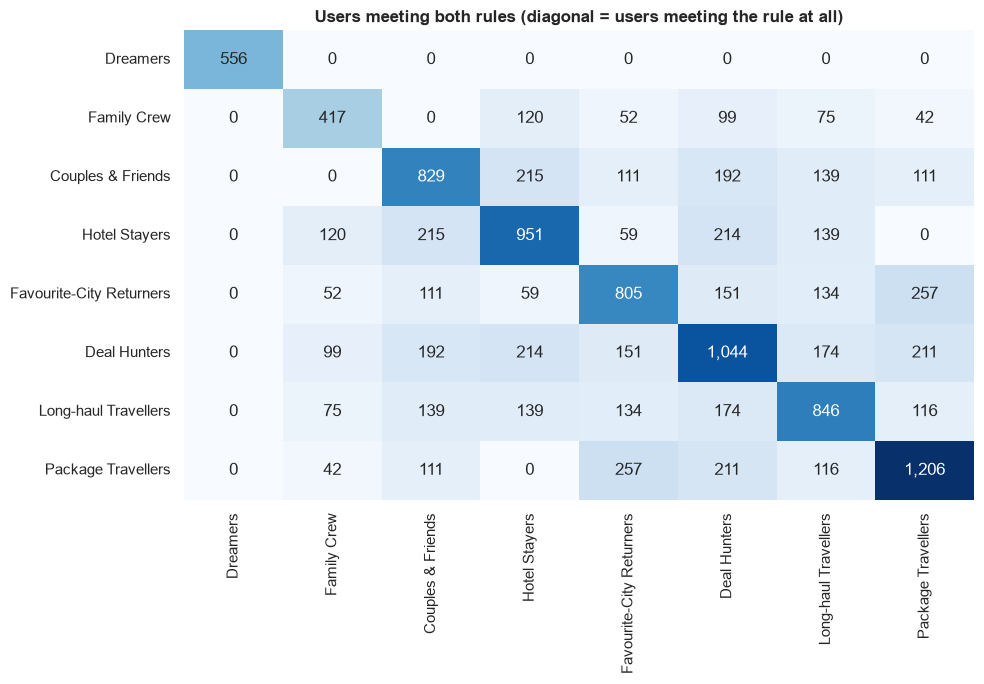

In [3]:
overlap = rule_flags.T.astype(int) @ rule_flags.astype(int)
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(overlap, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax); ax.grid(False)
ax.set_title("Users meeting both rules (diagonal = users meeting the rule at all)", fontweight="bold")
plt.tight_layout(); plt.show()

### 2.2 Segment profiles
Median of the key features per segment – each segment should stand out on *its own* marker.

,users,valid_trips,party_size,avg_bags,avg_distance_km,avg_nights,hotel_only_share,combo_share,weekend_start_share,discount_share,max_visits_same_city,avg_spend_per_trip_usd,age
segment,,,,,,,,,,,,,
Dreamers,556,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,28.0
Family Crew,417,2.0,1.80,0.5,1957.0,4.00,0.00,0.67,0.25,0.00,1.0,1499.09,42.0
Couples & Friends,829,3.0,1.67,0.5,2032.0,4.00,0.00,0.67,0.25,0.17,1.0,1393.64,41.0
Hotel Stayers,616,2.0,1.00,0.5,2003.0,6.00,0.67,0.25,0.00,0.00,1.0,976.88,38.0
Favourite-City Returners,604,4.0,1.00,0.5,2004.0,3.67,0.00,0.80,0.25,0.20,2.0,940.96,42.0
Deal Hunters,517,3.0,1.00,0.5,2045.0,3.33,0.00,1.00,0.25,0.50,1.0,890.59,43.0
Long-haul Travellers,377,2.0,1.00,0.5,3517.0,3.40,0.00,1.00,0.00,0.00,1.0,1142.20,41.0
Package Travellers,645,3.0,1.00,0.5,1883.0,3.33,0.00,1.00,0.33,0.20,1.0,925.27,42.0
All-rounders,1437,2.0,1.00,0.5,1828.0,3.50,0.00,0.75,0.20,0.00,1.0,774.82,42.0


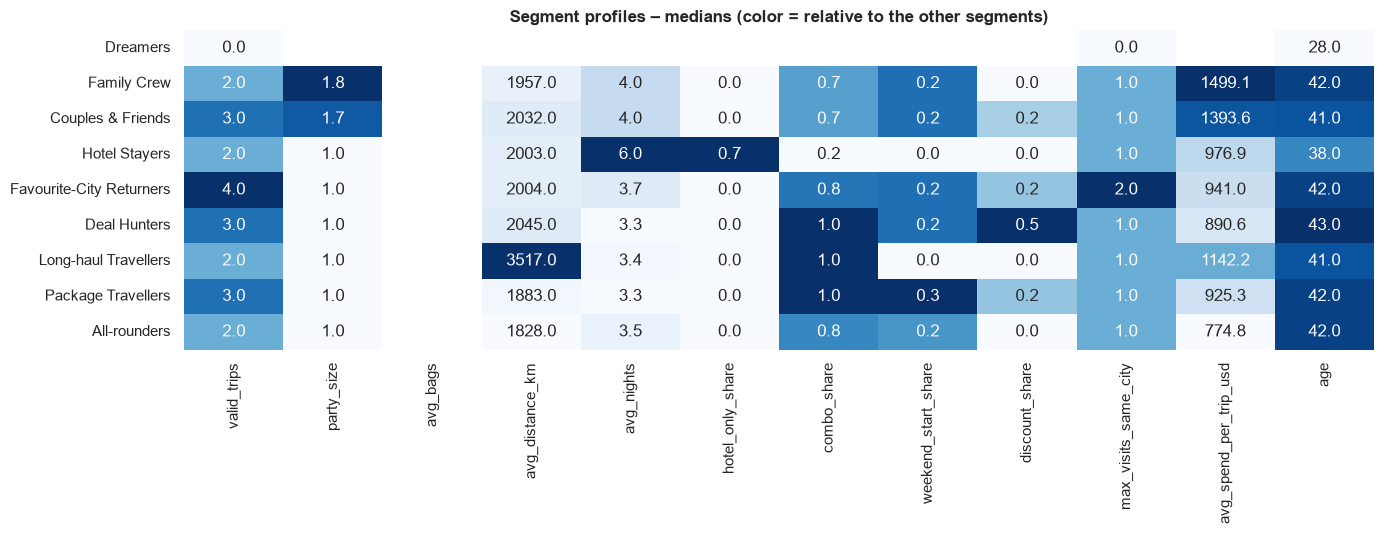

In [4]:
profile_cols = ["valid_trips", "party_size", "avg_bags", "avg_distance_km", "avg_nights", "hotel_only_share", "combo_share",
                "weekend_start_share", "discount_share", "max_visits_same_city", "avg_spend_per_trip_usd", "age"]
profile = users.groupby("segment")[profile_cols].median().reindex(SEGMENT_ORDER)
profile.insert(0, "users", sizes)
display(profile.round(2))

# Same profile as a heatmap: each column scaled 0–1, so the defining marker of every segment lights up
scaled = (profile[profile_cols] - profile[profile_cols].min()) / (profile[profile_cols].max() - profile[profile_cols].min())
fig, ax = plt.subplots(figsize=(14, 5.5))
sns.heatmap(scaled, annot=profile[profile_cols].round(1), fmt="", cmap="Blues", cbar=False, ax=ax); ax.grid(False)
ax.set_title("Segment profiles – medians (color = relative to the other segments)", fontweight="bold"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

## 3 – Habit or luck? Testing each rule against chance

### 3.1 The shuffle test

Most bookers have only 2–4 trips in six months. With so few trips, a user can look like a "deal hunter" or a "weekend traveller" just by luck. So before matching perks, every rule is tested against chance:

**The shuffle test:** all valid trips are dealt out to the users again at random – like shuffling a deck of cards. Every user keeps their number of trips, but which trip they get is random. If a rule finds about as many users in the shuffled data as in the real data, it is **luck**; if the real data has clearly more, it is a **habit** – and a perk built on it is backed by the data. The shuffle is repeated 50 times; a rule counts as a **habit** when the real data beats 95 % of the shuffles (the usual 5 % significance level).

*Each trip attribute is shuffled across all valid trips; checked bags and distance are shuffled together across flights, because they belong to the same flight.*

,real data,by luck (avg),luck range (90 %),real ÷ luck,verdict
Hotel Stayers: hotel-only ≥ 50 %,951,756,732–776,1.26,strong habit
Family / Couples: party size ≥ 1.5,1088,1038,1009–1068,1.05,habit
core: party size ≥ 2,413,364,344–383,1.13,habit
Favourite-City: same city ≥ 2 times,805,761,722–789,1.06,habit
core: same city ≥ 3 times,67,53,42–64,1.26,strong habit
"Long-haul Travellers: ≥ 3,000 km",846,774,742–801,1.09,habit
checked bags: ≥ 1 bag,1469,1455,1424–1492,1.01,luck
"Package Travellers: all trips flight + hotel, ≥ 3",1206,1031,1004–1054,1.17,habit
Deal Hunters: discounted ≥ 50 % & ≥ 2 trips,1044,1031,1003–1064,1.01,luck
Weekend Escapers (planned): Fri/Sat starts ≥ 50 %,1682,1684,1657–1708,1.00,luck


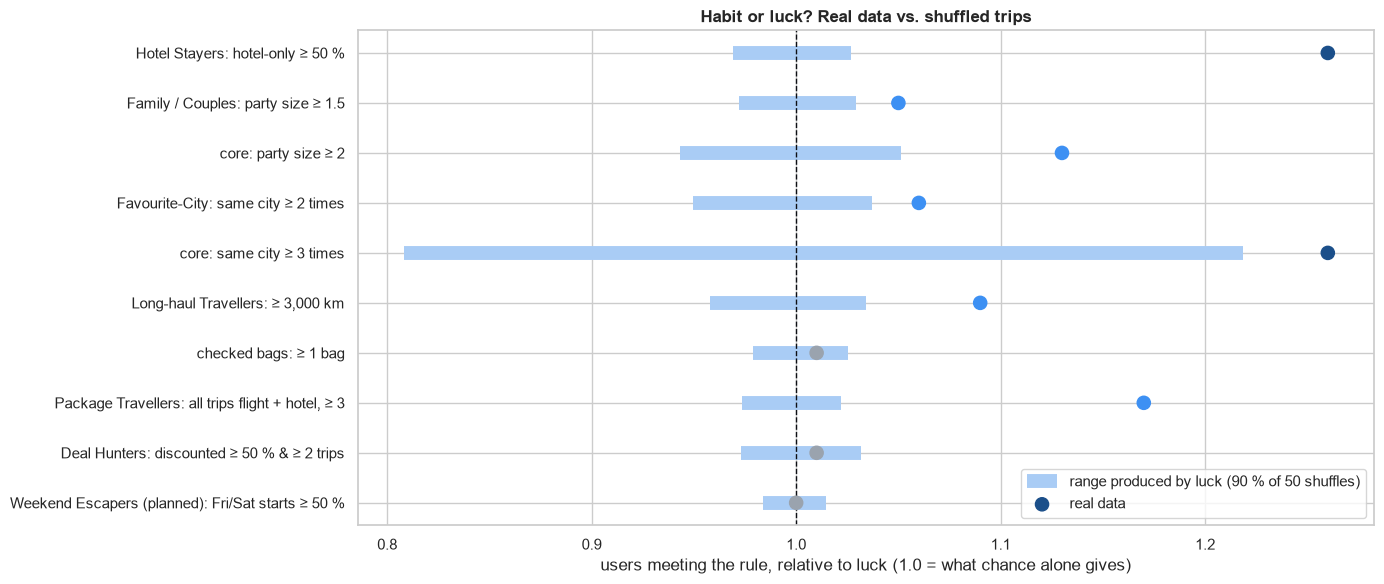

In [5]:
# --- 1) Trip table: one row per valid (kept) trip, with the attributes the rules use ---
trips = sessions[sessions["valid_booking"]].copy().reset_index(drop=True)
trips["hotel_only"] = trips["hotel_booked"] & ~trips["flight_booked"]   # True = hotel without flight
trips["package"] = trips["hotel_booked"] & trips["flight_booked"]       # True = flight + hotel together
trips["party"] = trips[["seats", "rooms"]].max(axis=1)                  # same definition as party_size in Part 2
trips["city"] = trips["trip_city"].str.lower().str.strip()             # same city spelled the same way

# --- 2) From trips to users: the same averages as in the user table (Part 2) ---
def user_metrics(t):
    """Per-user averages of the trip attributes the rules use."""
    g = t.groupby("user_id")
    m = pd.DataFrame({"trips": g.size(),                          # number of valid trips
                      "weekend": g["weekend_start"].mean(),       # share of trips starting Fri/Sat
                      "discount": g["discount_used"].mean(),      # share of trips with a discount
                      "hotel_only": g["hotel_only"].mean(),       # share of hotel-only trips
                      "package": g["package"].mean(),             # share of flight + hotel trips
                      "party": g["party"].mean(),                 # average party size
                      "bags": g["checked_bags"].mean(),           # average checked bags
                      "distance": g["distance_km"].mean()})       # average flight distance
    m["same_city"] = t.groupby(["user_id", "city"]).size().groupby("user_id").max()   # most trips to one city
    return m

# --- 3) The rules from section 2 (and some of their parts) – each one returns True/False per user ---
CHECKS = {
    "Hotel Stayers: hotel-only ≥ 50 %":                  lambda m: m["hotel_only"] >= 0.5,
    "Family / Couples: party size ≥ 1.5":                lambda m: m["party"] >= 1.5,
    "   core: party size ≥ 2":                           lambda m: m["party"] >= 2,
    "Favourite-City: same city ≥ 2 times":               lambda m: m["same_city"] >= 2,
    "   core: same city ≥ 3 times":                      lambda m: m["same_city"] >= 3,
    "Long-haul Travellers: ≥ 3,000 km":                  lambda m: m["distance"] >= 3000,
    "   checked bags: ≥ 1 bag":                          lambda m: m["bags"] >= 1,
    "Package Travellers: all trips flight + hotel, ≥ 3": lambda m: (m["package"] == 1) & (m["trips"] >= 3),
    "Deal Hunters: discounted ≥ 50 % & ≥ 2 trips":       lambda m: (m["discount"] >= 0.5) & (m["trips"] >= 2),
    "Weekend Escapers (planned): Fri/Sat starts ≥ 50 %": lambda m: m["weekend"] >= 0.5,
}
def count_users(m):
    """How many users meet each rule."""
    return {name: int(rule(m).sum()) for name, rule in CHECKS.items()}

# --- 4) Real data vs. 50 shuffles ---
real = count_users(user_metrics(trips))                     # rule counts in the real data
rng = np.random.default_rng(42)                             # fixed seed → same result every run
flight_rows = trips.index[trips["flight_booked"] & trips["distance_km"].notna()]
luck = []
for _ in range(50):
    t = trips.copy()
    # deal the trips out again at random: every user keeps their number of trips, but gets random ones
    for col in ["weekend_start", "discount_used", "hotel_only", "package", "party", "city"]:
        t[col] = rng.permutation(t[col].values)
    # bags and distance belong to the same flight → shuffle them together, only among flights
    t.loc[flight_rows, ["checked_bags", "distance_km"]] = trips.loc[rng.permutation(flight_rows), ["checked_bags", "distance_km"]].values
    luck.append(count_users(user_metrics(t)))               # rule counts in this shuffled version
luck = pd.DataFrame(luck)                                   # 50 rows (shuffles) × one column per rule

# --- 5) Compare: a rule is a habit if the real count beats 95 % of the shuffles ---
lo, hi = luck.quantile(0.05), luck.quantile(0.95)            # middle 90 % of what luck produces
habit = pd.DataFrame({"real data": pd.Series(real), "by luck (avg)": luck.mean().round(0).astype(int),
                      "luck range (90 %)": lo.round(0).astype(int).astype(str) + "–" + hi.round(0).astype(int).astype(str)})
habit["real ÷ luck"] = (habit["real data"] / habit["by luck (avg)"]).round(2)    # 1.26 = 26 % more users than luck gives
habit["verdict"] = np.select([habit["real data"] <= hi, habit["real ÷ luck"] >= 1.2],
                             ["luck", "strong habit"], default="habit")
display(habit)

# --- 6) Same result as a picture: light bar = what luck alone produces, dot = real data ---
ratio_lo, ratio_hi = lo / luck.mean(), hi / luck.mean()     # luck range on the same "÷ luck" scale as the dots
fig, ax = plt.subplots(figsize=(14, 6))
y = np.arange(len(habit))[::-1]                             # first rule at the top
ax.hlines(y, ratio_lo, ratio_hi, color=PALETTE[1], lw=10, label="range produced by luck (90 % of 50 shuffles)")
colors = {"strong habit": PALETTE[3], "habit": PALETTE[0], "luck": "#9AA3AE"}
ax.scatter(habit["real ÷ luck"], y, s=90, zorder=3, color=[colors[v] for v in habit["verdict"]], label="real data")
ax.axvline(1, color=PALETTE[4], ls="--", lw=1)              # 1.0 = exactly what luck gives
ax.set_yticks(y); ax.set_yticklabels(habit.index); ax.set_xlabel("users meeting the rule, relative to luck (1.0 = what chance alone gives)")
ax.set_title("Habit or luck? Real data vs. shuffled trips", fontweight="bold"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

**What the shuffle test shows** *(numbers from my run, random seed 42)*
- **Strong habit – Hotel Stayers:** 951 users book mostly hotel-only trips, against ~756 by luck (+26 %). The clearest behavioral marker in the data → strongest support for the **free hotel meal**.
- **Habit – package travel:** booking *every* trip as flight + hotel (3+ trips) is more common than luck gives (1,206 vs ~1,031, +17 %) → backs the **1 night free hotel with flight**, the one perk that needs exactly this booking.
- **Habit – long distances and group travel:** an average of 3,000+ km (846 vs ~774) and a party size of 2+ (413 vs ~364) are real habits. At the segment threshold of 1.5 the effect is small (about +5 %) – the segment's *core* (2+) is the clear habit.
- **Small effect – repeat cities:** 805 users visit the same city twice – only slightly more than luck alone gives (~761), because most repeat visits come from popular cities (New York, …). Users with 3+ visits (67 vs ~53 by luck) point to a small true core.
- **Luck – checked bags, discounts and weekends:** these patterns are as common in shuffled data as in the real data. With 2–4 trips per user, "mostly discounted" or "mostly weekends" happens by chance.

**Why this matters for Elena:** the segments still assign one perk to every customer – recent behavior is the best signal available. But the strength of the evidence differs per perk, and that is exactly Elena's first question (*"does the data support the perks?"*). The perks backed by habits can be rolled out; the ones built on luck-level patterns should be tested first (section 4).

In [6]:
# Discounts from one more angle: does offering a discount make people book more?
# Cancellation sessions are left out: they always carry both discount flags (data artefact) and repeat the booking flags
shopping = sessions[~sessions["cancellation"]]
offer_effect = pd.DataFrame({
    # share of sessions that book a flight – with vs. without a flight discount on offer
    "flight booked – discount offered":     shopping.loc[shopping["flight_discount"], "flight_booked"].mean(),
    "flight booked – no discount":          shopping.loc[~shopping["flight_discount"], "flight_booked"].mean(),
    # same for hotels
    "hotel booked – discount offered":      shopping.loc[shopping["hotel_discount"], "hotel_booked"].mean(),
    "hotel booked – no discount":           shopping.loc[~shopping["hotel_discount"], "hotel_booked"].mean()},
    index=["share of sessions"]).T.mul(100).round(1)             # in %
display(offer_effect)

,share of sessions
flight booked – discount offered,23.8
flight booked – no discount,29.1
hotel booked – discount offered,31.1
hotel booked – no discount,29.2


Offering a discount does **not** clearly raise booking rates: flights are booked *less* often in sessions with a flight discount (23.8 % vs 29.1 %), hotels only slightly more often (31.1 % vs 29.2 %). Together with the shuffle test: the data shows no group of customers that reacts especially strongly to discounts. Elena's *exclusive discounts* perk is therefore the one with the **weakest behavioral evidence** – a candidate for an A/B test rather than a full rollout.

**Booking itself – habit or luck?** The brief suggests that a *low conversion rate* (few sessions ending in a booking) could signal price sensitivity. Two checks: is converting a habit, and is it linked to discount use?

In [7]:
# Conversion = share of a user's shopping sessions (no cancellations) that end in a booking
conversion = (shopping.assign(booked=shopping["flight_booked"] | shopping["hotel_booked"])   # booked anything?
              .groupby("user_id").agg(sessions=("booked", "size"), bookings=("booked", "sum")))
p_book = conversion["bookings"].sum() / conversion["sessions"].sum()   # overall conversion of all sessions
n_s = conversion["sessions"]                                           # sessions per user
conversion["rate"] = conversion["bookings"] / n_s                      # conversion per user
print(f"Shopping sessions that end in a booking: {p_book:.1%}")

# Chance model: every session books with the same probability p_book (binomial distribution)
display(pd.DataFrame({
    "real": [(conversion["rate"] >= 0.5).sum(), (conversion["bookings"] == 0).sum()],
    "expected by chance": [(1 - binom.cdf(np.ceil(n_s * 0.5) - 1, n_s, p_book)).sum(),   # P(≥ half of sessions book)
                           binom.pmf(0, n_s, p_book).sum()]},                            # P(no session books)
    index=["users booking in ≥ 50 % of their sessions", "users who never book"]).round(0).astype(int))

# Is low conversion a sign of bargain hunting (brief, week 2)? → correlation with discount use
booker_ids = users.index[~users["is_dreamer"]]
print(f"Conversion vs discount share (bookers): r = {conversion['rate'].reindex(booker_ids).corr(users.loc[booker_ids, 'discount_share']):.2f}")

Shopping sessions that end in a booking: 33.1%


,real,expected by chance
users booking in ≥ 50 % of their sessions,1598,1382
users who never book,458,236


Conversion vs discount share (bookers): r = -0.02


**Booking is a habit – but not a sign of bargain hunting.** A third of shopping sessions end in a booking, and how often someone books is clearly *not* luck: about **twice as many users never book** as chance predicts – so the **Dreamers are a real group**, not just unlucky browsers – and more users book in at least half of their sessions than chance gives. But conversion is not linked to discount use (r ≈ 0), so the brief's idea of low conversion as a price-sensitivity signal does not hold in TravelTide's data. Conversion is not added as a segment feature: with ~8 sessions per user it equals the number of trips (Part 2, section 5).

### 3.2 Why there is no Weekend Escapers segment
I planned a segment for short trips that start on Friday or Saturday (≥ 50 % of trips, ≤ 3 nights). Before keeping it, I checked whether weekend travel is a habit or chance: 28.7 % of all trips start on a Friday or Saturday – exactly what random start days would give (2 of 7 days = 28.6 %). Given each user's number of trips, chance alone predicts as many bookers with ≥ 50 % weekend starts as the data has (cell below) – the shuffle test above agrees. With only 2–4 trips per user, "mostly weekends" happens by luck: a user with 2 trips has a 49 % chance.

→ **Weekend Escapers dropped**; `weekend_start_share` is also left out of K-Means (section 5), because a feature that is pure chance only adds noise.

In [8]:
# Chance model for weekend trips: if start days were random, how many users would have ≥ 50 % weekend starts?
bookers_all = users[~users["is_dreamer"]]
n = bookers_all["valid_trips"]                                          # trips per user
p = (bookers_all["weekend_start_share"] * n).sum() / n.sum()          # weekend share of all trips
needed = np.ceil(n * 0.5)                                               # weekend trips needed for "≥ 50 %"
expected = (1 - binom.cdf(needed - 1, n, p)).sum()                      # sum of each user's chance (binomial)
observed = (bookers_all["weekend_start_share"] >= 0.5).sum()            # real number of users
print(f"Weekend share of all trips: {p:.1%} (2 of 7 days = 28.6 %)")
print(f"Bookers with ≥ 50 % weekend starts – real: {observed:,} | expected by chance: {expected:,.0f}")
print(f"Chance that a user with 2 trips has ≥ 1 weekend start: {1 - (1 - p) ** 2:.0%}")   # 1 – P(no weekend trip)

Weekend share of all trips: 28.7% (2 of 7 days = 28.6 %)
Bookers with ≥ 50 % weekend starts – real: 1,682 | expected by chance: 1,681
Chance that a user with 2 trips has ≥ 1 weekend start: 49%


### 3.3 Long-haul Travellers: distance, not bags
Checked bags and long distances look like they belong together – but the data says otherwise. Most users who check 1+ bag on average fly well under 3,000 km, and bags hardly relate to distance or party size (cell below). The shuffle test (3.1) confirms it: flying long distances is a habit, checking bags is luck.

→ The segment is defined by **distance only** (≥ 3,000 km on average). Long-haul travellers don't check more bags than other bookers either (median 0.5 per trip), so the *free checked bag* doesn't fit what the data proves. Their core perk is a **new perk that fits the distance habit: an extra-legroom seat** on long flights; the free checked bag becomes their pilot perk (section 4).

In [9]:
# Do checked bags go together with long distances?
bags_rule = bookers_all["avg_bags"] >= 1
dist_rule = bookers_all["avg_distance_km"] >= 3000
# users with 1+ bag on average – how many of them fly under 3,000 km?
print(f"Bookers with ≥ 1 bag on average: {bags_rule.sum():,} – of them below 3,000 km: {(bags_rule & ~dist_rule).sum():,} "
      f"(median distance {bookers_all.loc[bags_rule & ~dist_rule, 'avg_distance_km'].median():,.0f} km)")
# do bags go together with distance or party size? (r close to 0 = no)
print(f"Correlation of bags with distance: r = {bookers_all['avg_bags'].corr(bookers_all['avg_distance_km']):.2f} | "
      f"with party size: r = {bookers_all['avg_bags'].corr(bookers_all['party_size']):.2f}")
# do long-haul travellers check more bags than everyone else?
print(f"Median bags per trip – long-haul travellers: {bookers_all.loc[dist_rule, 'avg_bags'].median()} | all bookers: {bookers_all['avg_bags'].median()}")

Bookers with ≥ 1 bag on average: 1,469 – of them below 3,000 km: 1,180 (median distance 1,817 km)
Correlation of bags with distance: r = 0.04 | with party size: r = 0.18
Median bags per trip – long-haul travellers: 0.5 | all bookers: 0.5


## 4 – Perk mapping (core perks from Elena's list – plus one new perk where the data points elsewhere)
| Segment | Core perk | Pilot perk (A/B test) | Evidence (section 3) |
|---|---|---|---|
| Dreamers | No cancellation fees | 48-h Fare Lock | **strong** – first-time bookers cancel ~3× more often than chance (5.6) |
| Family Crew | Free hotel meal | Family fare | moderate – group travel of 2+ is a habit |
| Couples & Friends | No cancellation fees | Bring-a-friend | moderate – group travel of 2+ is a habit |
| Hotel Stayers | Free hotel meal | Welcome dinner on night 1 | **strong** – hotel-only stays, +26 % vs luck |
| Favourite-City Returners | 1 night free hotel with flight | City stamp card | small – slightly above luck (mostly popular cities) |
| Deal Hunters | Exclusive discounts | Price-drop guarantee | weak – discount use is at chance level → test first |
| Long-haul Travellers | **Extra-legroom seat** *(new)* | Free checked bag | habit – long distances (+9 % vs luck); they don't check more bags (3.3), so the new perk fits the proven behavior |
| Package Travellers | 1 night free hotel with flight | Free airport transfer | habit – every trip flight + hotel, more than luck (section 3) |
| All-rounders | highest perk score (4.1) | – | no dominant habit |

**Pilot spotlight – the City Stamp Card (Favourite-City Returners)**
A digital punch card for one city – like a coffee-shop card: every trip to the same city earns a stamp, and the **3rd trip unlocks a local extra** (free airport transfer, a partner-restaurant voucher or a city experience). Example email hook: *"New York is your second home – your 3rd stay comes with a thank-you."*

- **Why it fits:** it rewards exactly what this segment does – coming back – and it is cheap, because the reward only follows repeat bookings.
- **Why pilot, not core:** the evidence for the segment is small (repeat visits are only slightly above luck, mostly popular cities – section 3.1), and a reward after the 3rd trip is a weaker hook for a sign-up email than an immediate perk. So the core stays *1 night free hotel with flight*, and the stamp card is tested against it.

In [10]:
CORE_PERK = {"Dreamers": "No cancellation fees", "Family Crew": "Free hotel meal",
             "Couples & Friends": "No cancellation fees", "Hotel Stayers": "Free hotel meal",
             "Favourite-City Returners": "1 night free hotel with flight",
             "Deal Hunters": "Exclusive discounts", "Long-haul Travellers": "Extra-legroom seat",
             "Package Travellers": "1 night free hotel with flight", "All-rounders": "assigned by perk score (4.1)"}
PILOT_PERK = {"Dreamers": "48-h Fare Lock", "Family Crew": "Family fare", "Couples & Friends": "Bring-a-friend",
              "Hotel Stayers": "Welcome dinner on night 1", "Favourite-City Returners": "City stamp card",
              "Deal Hunters": "Price-drop guarantee", "Long-haul Travellers": "Free checked bag",
              "Package Travellers": "Free airport transfer"}
users["core_perk"] = users["segment"].map(CORE_PERK)
display(users["core_perk"].value_counts().to_frame("users"))

,users
core_perk,
assigned by perk score (4.1),1437
No cancellation fees,1385
1 night free hotel with flight,1249
Free hotel meal,1033
Exclusive discounts,517
Extra-legroom seat,377


### 4.1 Perk scores: one perk for every customer
Elena needs **one perk per customer** – also for the All-rounders, who have no single dominant habit. Following the brief's *fuzzy segmentation* idea, every booker gets a **score for each of Elena's five perks**, built from the features that point to it:

| Perk | Score = average of … (standardized) |
|---|---|
| Free hotel meal | nights per stay, hotel-only share |
| Free checked bag | bags per trip |
| No cancellation fees | cancel rate, party size |
| Exclusive discounts | discount share |
| 1 night free hotel with flight | package share, visits to the same city |

Each feature is standardized (0 = the average booker, +1 = one standard deviation above), so the score reads as *"how far above the average booker is this customer on this perk's behavior"*; the five scores are then put on the same scale, so a perk built on one feature doesn't win more often than one built on two. **All-rounders get the perk with their highest score.** Segment members keep their rule perk – the rules are the stronger evidence – but their scores are used as a cross-check. Dreamers have no trip data and keep their rule perk.

All-rounders assigned by score: 1,437 → {'Free checked bag': 506, '1 night free hotel with flight': 306, 'Free hotel meal': 238, 'Exclusive discounts': 206, 'No cancellation fees': 181}
Cross-check: for 57% of segment members the highest score points to their rule perk


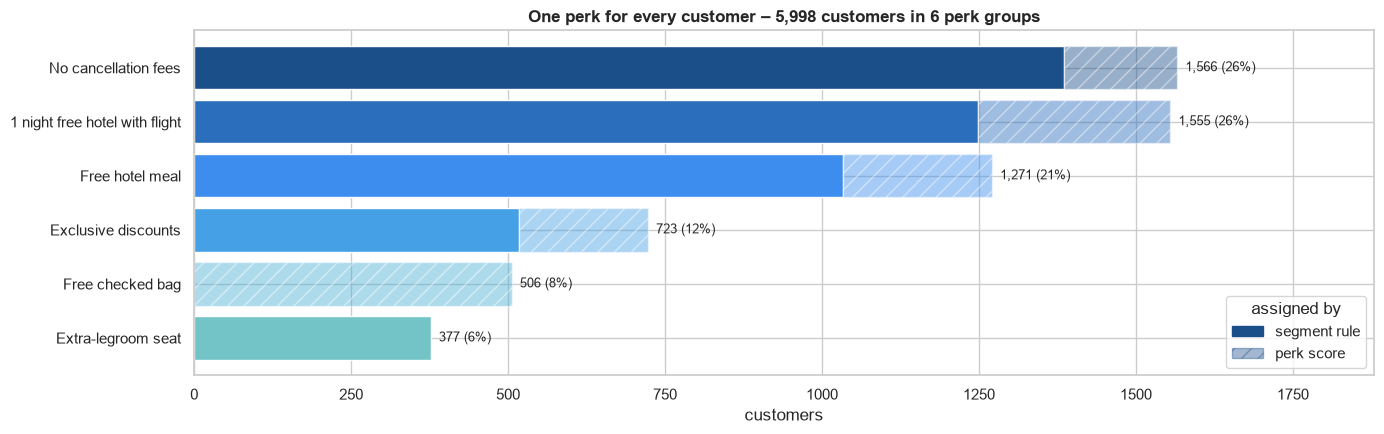

In [11]:
# --- 1) Which features point to which of Elena's perks ---
PERK_FEATURES = {"Free hotel meal":                ["avg_nights", "hotel_only_share"],
                 "Free checked bag":               ["avg_bags"],
                 "No cancellation fees":           ["cancel_rate", "party_size"],
                 "Exclusive discounts":            ["discount_share"],
                 "1 night free hotel with flight": ["combo_share", "max_visits_same_city"]}
score_cols = sorted({col for cols in PERK_FEATURES.values() for col in cols})   # all features used once

# --- 2) Standardize the features: 0 = average booker, +1 = one standard deviation above ---
bookers_scored = users[~users["is_dreamer"]]                    # Dreamers have no trip data
Z = pd.DataFrame(StandardScaler().fit_transform(bookers_scored[score_cols].fillna(bookers_scored[score_cols].median())),
                 columns=score_cols, index=bookers_scored.index)              # median = neutral, as in K-Means

# --- 3) One score per perk = average of its features; then all five put on the same scale ---
perk_scores = pd.DataFrame({perk: Z[cols].mean(axis=1) for perk, cols in PERK_FEATURES.items()})
perk_scores = (perk_scores - perk_scores.mean()) / perk_scores.std()   # same scale for all five, so one-feature perks don't win more often
best_perk = perk_scores.idxmax(axis=1)                                 # the perk with the highest score per user

# --- 4) Final perk: rule perk for segment members, best score for All-rounders ---
users["perk"] = users["core_perk"]
users["perk_source"] = "segment rule"
all_rounders = users.index[users["segment"] == "All-rounders"]
users.loc[all_rounders, "perk"] = best_perk.loc[all_rounders]
users.loc[all_rounders, "perk_source"] = "perk score"
users["pilot_perk"] = users["segment"].map(PILOT_PERK)          # All-rounders: no pilot perk

# --- 5) Cross-check: do the scores agree with the rule perk for segment members? ---
members = bookers_scored.index[(bookers_scored["segment"] != "All-rounders") &
                               users.loc[bookers_scored.index, "core_perk"].isin(PERK_FEATURES)]   # segments with one of Elena's five perks
agree = (best_perk.loc[members] == users.loc[members, "core_perk"]).mean() # share of members whose highest score points to their rule perk
print(f"All-rounders assigned by score: {len(all_rounders):,} → {best_perk.loc[all_rounders].value_counts().to_dict()}")
print(f"Cross-check: for {agree:.0%} of segment members the highest score points to their rule perk")

# --- 6) Final picture: every customer in one perk group, split by where the assignment comes from ---
final = users.groupby(["perk", "perk_source"]).size().unstack(fill_value=0)                  # customers per perk and source
final = final.loc[final.sum(axis=1).sort_values().index, ["segment rule", "perk score"]]    # smallest perk at the bottom
perk_colors = [TT_CMAP(x) for x in np.linspace(0.4, 1, len(final))]   # skip the palest shades, so the light 'score' part stays visible
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.barh(final.index, final["segment rule"], color=perk_colors, label="segment rule")                    # solid = assigned by segment rule
ax.barh(final.index, final["perk score"], left=final["segment rule"], color=perk_colors, alpha=0.45,
        hatch="//", edgecolor="white", label="perk score")                                              # light = assigned by perk score
for i, total in enumerate(final.sum(axis=1)):
    ax.text(total, i, f"  {total:,} ({total / len(users):.0%})", va="center", fontsize=9)               # total per perk
ax.set_xlim(0, final.sum(axis=1).max() * 1.2); ax.set_ylabel(""); ax.set_xlabel("customers")
ax.set_title(f"One perk for every customer – {len(users):,} customers in {users['perk'].nunique()} perk groups", fontweight="bold")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=PALETTE[3], label="segment rule"), Patch(color=PALETTE[3], alpha=0.4, hatch="//", label="perk score")],
          title="assigned by", loc="lower right")
plt.tight_layout(); plt.show()

In [12]:
# Redundancy check (brief): are two perks so correlated that they are really one perk? (bookers only)
display(perk_scores.corr().round(2))

,Free hotel meal,Free checked bag,No cancellation fees,Exclusive discounts,1 night free hotel with flight
Free hotel meal,1.00,0.00,0.09,-0.01,-0.52
Free checked bag,0.00,1.00,0.12,0.00,-0.01
No cancellation fees,0.09,0.12,1.00,0.02,-0.11
Exclusive discounts,-0.01,0.00,0.02,1.00,0.04
1 night free hotel with flight,-0.52,-0.01,-0.11,0.04,1.00


**Redundancy check:** no two perks overlap – the correlations between the perk scores are close to 0 (|r| ≤ 0.12), except free hotel meal vs 1 night free hotel with flight (r = −0.52). That one is negative: the two hotel perks speak to opposite customers – hotel-only stayers vs package bookers – so they complement each other.

**Result:** all customers now have exactly one perk, in six perk groups – Elena's five plus the extra-legroom seat for Long-haul Travellers (chart). The All-rounders spread over all five of Elena's perks, so no perk is filled only by "leftovers". For more than half of the segment members (57 %) the scores point to the same perk as the rules – where they don't, the rule wins, because it is built on a tested habit (section 3). The largest share of All-rounders lands on the free checked bag (they check bags but show no other stand-out habit) – since bag-checking is not a proven habit (3.1), this is the best available match, not strong evidence. Overall, the All-rounders' scores are modest, so their perk is the *best available* match – a good group for the A/B test.

## 5 – K-Means: does the data find the same groups?

The rules above are my hypotheses. K-Means groups users **only by similarity of their features**, without knowing the rules. If its clusters line up with the rule segments, the segments reflect real behavior and are not just my thresholds.

**Setup decisions**
- **Bookers only (5,442 users):** Dreamers have no trip data – they are a segment by definition.
- **9 behavioral features, one per signal** (based on the correlation check in Part 2, section 5, and the habit check in section 3):
  - kept `avg_distance_km`, left out `long_haul_share` (r = 0.7, same signal)
  - left out `avg_session_min` and `avg_page_clicks` – engagement mainly shows *whether* someone books (Part 1, 5.1.3), and both are driven by cancellation sessions
  - left out spend – it is a result of party size and nights, not a behavior of its own
  - left out `weekend_start_share` – pure chance (section 3.2), it would only add noise
  - left out demographics (age, family status) – they describe the segments afterwards
- **Missing values → median, for K-Means only:** K-Means cannot handle empty cells. Hotel-only users have no bags or distance; the median gives them a *neutral* value, so the missing flight does not drive their cluster – `hotel_only_share` already captures that they don't fly. The saved table keeps the real empty values.
- **Standard scaling features** (mean 0, std 1): otherwise distance (thousands of km) would outweigh shares between 0 and 1.

In [13]:
KM_FEATURES = ["party_size", "avg_bags", "avg_distance_km", "avg_nights", "hotel_only_share",
               "discount_share", "max_visits_same_city", "valid_trips", "cancel_rate"]
K = 8   # = 7 booker segments + All-rounders (Dreamers are not clustered), see 5.1
bookers = users[~users["is_dreamer"]].copy()
X = bookers[KM_FEATURES].fillna(bookers[KM_FEATURES].median())   # median only for the model, see above
X_scaled = StandardScaler().fit_transform(X)
print(f"K-Means input: {X_scaled.shape[0]:,} bookers × {X_scaled.shape[1]} features | "
      f"cells filled with the median: {bookers[KM_FEATURES].isna().sum().sum():,}")

K-Means input: 5,442 bookers × 9 features | cells filled with the median: 934


### 5.1 How many clusters? (k = 2 – 10)
Three checks for every k:
- **Silhouette score** (−1 to 1, higher = better): how clearly each user belongs to its own cluster rather than the next one
- **Davies-Bouldin index** (≥ 0, lower = better): how compact and well separated the clusters are
- **Inertia** (elbow): total distance of users to their cluster center – always falls with more clusters; a bend shows where extra clusters stop adding much

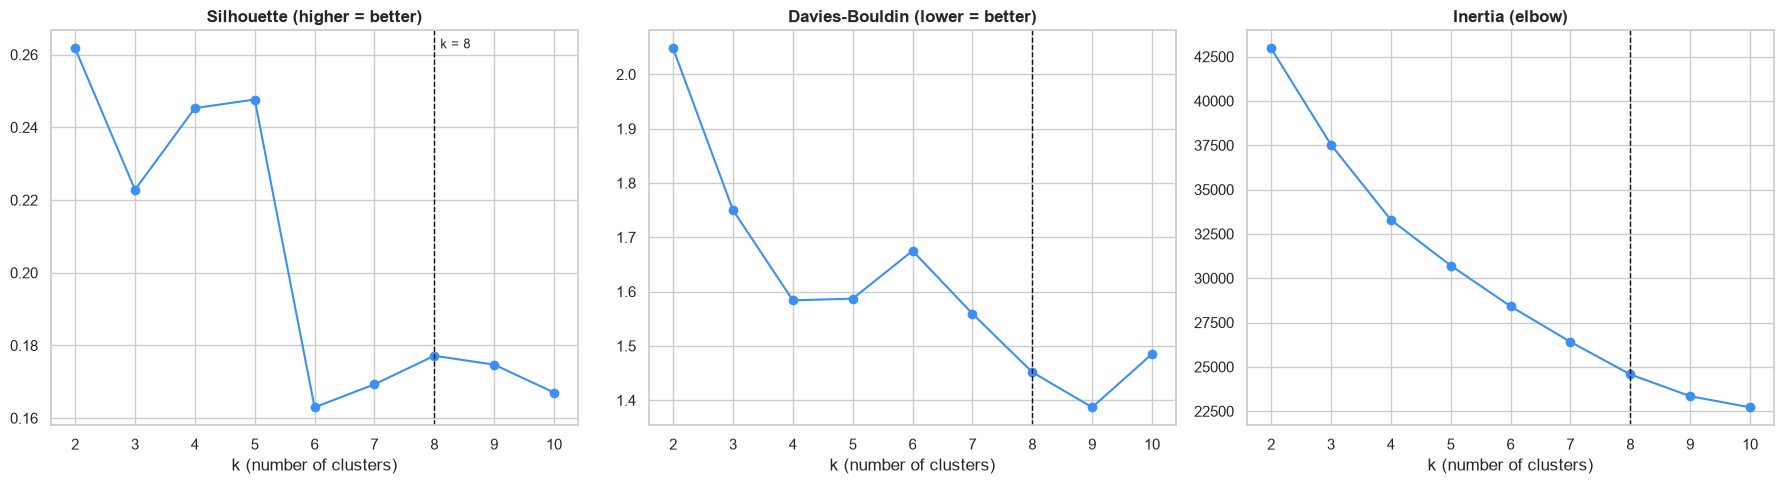

,silhouette,davies_bouldin,inertia,smallest_cluster
k,,,,
2,0.262,2.048,42963.968,958
3,0.223,1.750,37529.102,797
4,0.245,1.584,33291.289,408
5,0.248,1.587,30715.273,404
6,0.163,1.675,28414.653,396
7,0.169,1.559,26407.134,394
8,0.177,1.451,24572.112,83
9,0.175,1.387,23345.444,83
10,0.167,1.485,22716.391,84


In [14]:
scores = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_scaled)
    scores.append({"k": k, "silhouette": silhouette_score(X_scaled, km.labels_),
                   "davies_bouldin": davies_bouldin_score(X_scaled, km.labels_), "inertia": km.inertia_,
                   "smallest_cluster": np.bincount(km.labels_).min()})
scores = pd.DataFrame(scores).set_index("k")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, col, title in zip(axes, ["silhouette", "davies_bouldin", "inertia"],
                          ["Silhouette (higher = better)", "Davies-Bouldin (lower = better)", "Inertia (elbow)"]):
    ax.plot(scores.index, scores[col], marker="o", color=PALETTE[0])
    ax.axvline(K, color=PALETTE[4], ls="--", lw=1)
    ax.set_title(title, fontweight="bold"); ax.set_xlabel("k (number of clusters)")
axes[0].text(K + 0.1, scores["silhouette"].max(), f"k = {K}", fontsize=9)
plt.tight_layout(); plt.show()
display(scores.round(3))

**Reading the scores:**
- All silhouette scores are **low (0.17 – 0.26)**: TravelTide's customers do not fall into sharply separated groups – behavior is a *continuum*. This is common for customer data and is the reason the perks are assigned with clear **rules**, with K-Means as a check.
- The best silhouette is at **k = 2** – but two groups cannot carry five perks. k = 4–5 have a local peak (≈ 0.25); k = 5 is the "one cluster per perk" option.
- Davies-Bouldin keeps improving up to k = 9, the elbow has no sharp bend.
- Leaving out the chance-level weekend feature raised the scores (silhouette at k = 8: 0.177, vs 0.149 with it).

*The Davies-Bouldin index was not part of the course: I added it from scikit-learn's clustering evaluation metrics (`sklearn.metrics.davies_bouldin_score`) as a second opinion, because the silhouette score looks at single users while Davies-Bouldin looks at whole clusters (how compact they are and how far apart from their closest neighbour).*

**Choice: k = 8** – the same number of groups as my booker segments (7 rule segments + All-rounders), so clusters and rules can be compared one to one. k = 8 also scores better than k = 7 (silhouette 0.177 vs 0.169, Davies-Bouldin 1.45 vs 1.56). Its silhouette is lower than at k = 5, but k = 5 finds only three of the rule segments (Hotel Stayers, Favourite-City Returners, group travellers). The smallest cluster (83 users) are the extreme long-haul flyers.

### 5.2 What does each cluster stand for?
Average of each feature per cluster, **standardized**: 0 = average booker, +1 = one standard deviation above. The darkest cell in a row is what defines the cluster; the cluster names are generated from it.

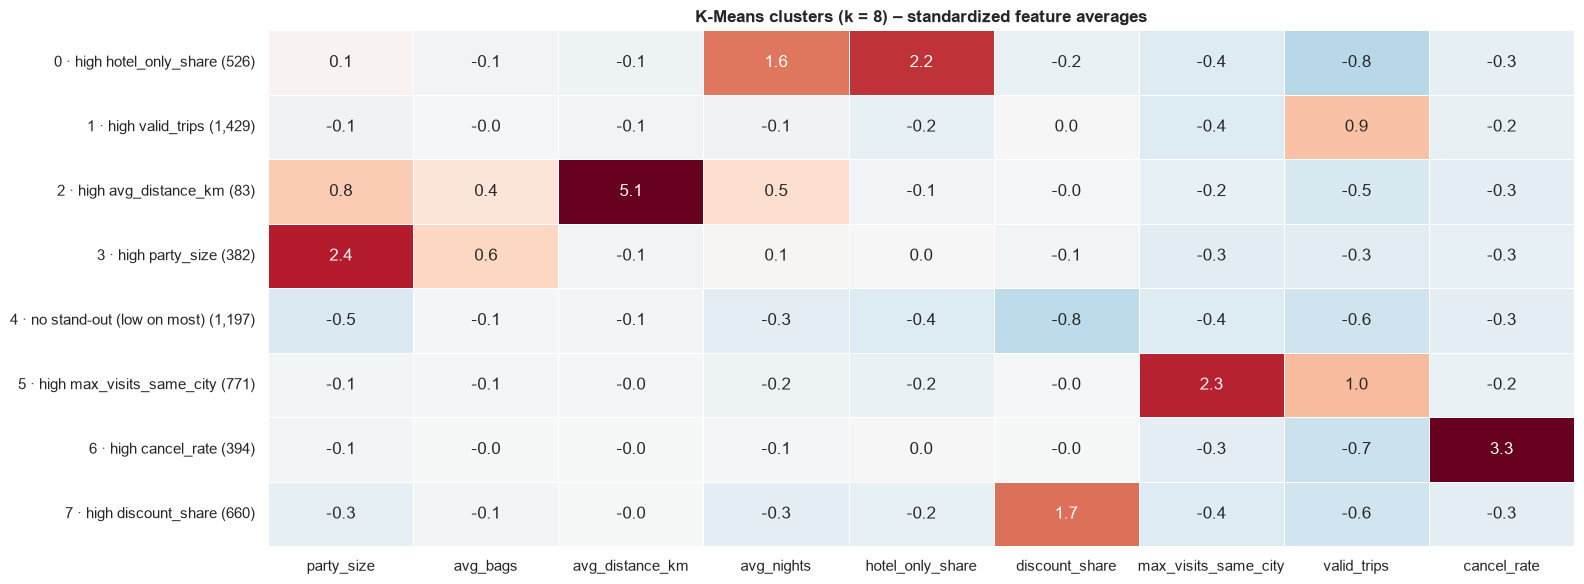

In [15]:
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X_scaled)
bookers["cluster"] = kmeans.labels_

centers = pd.DataFrame(X_scaled, columns=KM_FEATURES, index=bookers.index).groupby(bookers["cluster"]).mean()
# name each cluster after its strongest feature (clusters without a value above +0.5 = "no stand-out")
top = centers.idxmax(axis=1)
names = {c: (f"high {top[c]}" if centers.loc[c, top[c]] > 0.5 else "no stand-out (low on most)") for c in centers.index}
centers.index = [f"{c} · {names[c]} ({(bookers['cluster'] == c).sum():,})" for c in centers.index]

fig, ax = plt.subplots(figsize=(16, 6))
sns.heatmap(centers, annot=True, fmt=".1f", cmap="RdBu_r", center=0, vmin=-3, vmax=3, cbar=False, linewidths=0.5, ax=ax)
ax.set_title(f"K-Means clusters (k = {K}) – standardized feature averages", fontweight="bold"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

### 5.3 Clusters vs. rule segments
Each column is one cluster (100 %): which rule segments do its users come from? A cluster dominated by one segment means K-Means found that segment **on its own**.

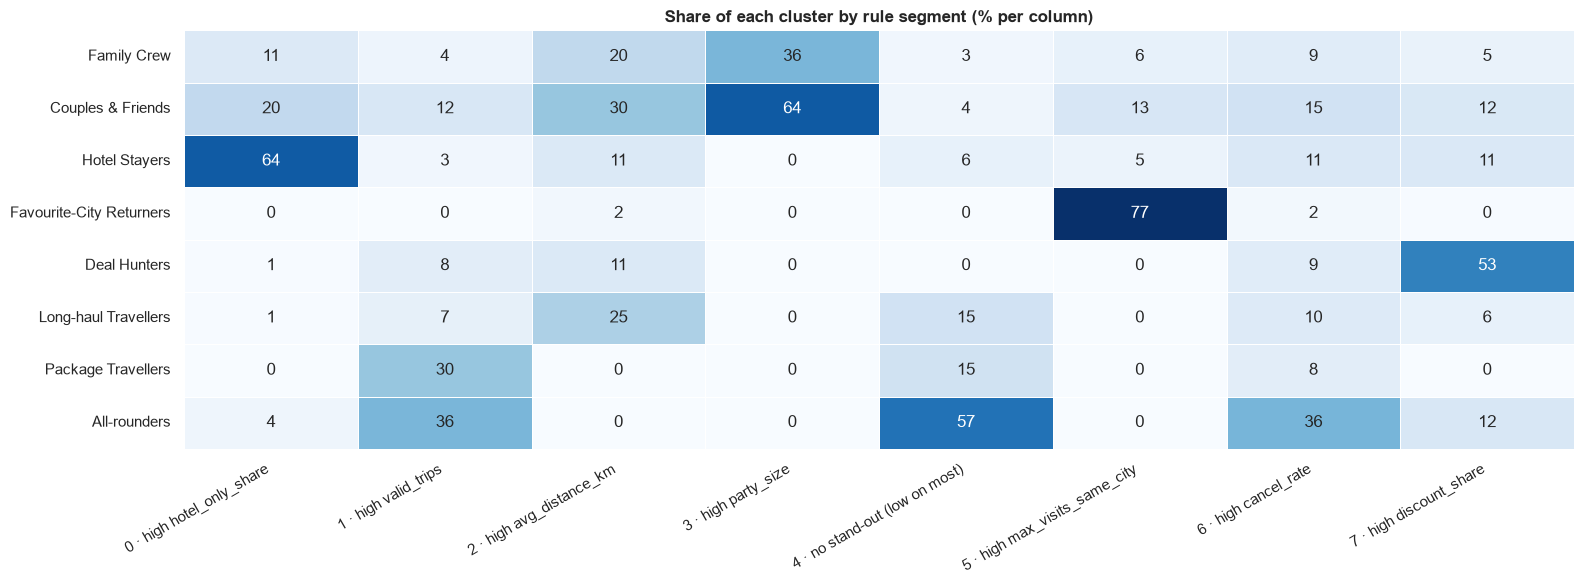

In [16]:
cross = pd.crosstab(bookers["segment"], bookers["cluster"].map(lambda c: f"{c} · {names[c]}"), normalize="columns") * 100
cross = cross.reindex([s for s in SEGMENT_ORDER if s in cross.index])

fig, ax = plt.subplots(figsize=(16, 6))
sns.heatmap(cross, annot=True, fmt=".0f", cmap="Blues", cbar=False, linewidths=0.5, ax=ax)
ax.set_title("Share of each cluster by rule segment (% per column)", fontweight="bold")
ax.set_xlabel(""); ax.set_ylabel("")
plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

**What K-Means confirms – and what it doesn't** *(numbers from my run with random_state = 42)*

| Cluster defined by | Matching rule segment | Agreement |
|---|---|---|
| high `max_visits_same_city` | Favourite-City Returners | 592 of 604 returners (98 %) in one cluster; 77 % of that cluster |
| high `party_size` | Family Crew + Couples & Friends | 100 % of the cluster |
| high `hotel_only_share` + long `avg_nights` | Hotel Stayers | 64 % of the cluster |
| high `discount_share` | Deal Hunters | 53 % of the cluster |
| high `valid_trips` | Package Travellers + All-rounders | 431 of 645 Package Travellers (67 %) sit here |
| high `avg_distance_km` (≈ 8,000 km) | extreme long-haul flyers | small cluster of 83 users – many travel in groups, so the priority order puts them in Family Crew / Couples & Friends first |
| high `cancel_rate` | – no rule segment | 394 bookers → see 5.6 |
| no stand-out (low on most) | All-rounders, Long-haul Travellers | mixed |

- **4 of my 7 booker segments appear as their own cluster** – K-Means finds them without knowing the rules.
- **Package Travellers sit inside the frequent-traveller cluster:** K-Means groups them by *how often* they travel, not by trip type – they are the frequent travellers who always book the full package.
- **Long-haul Travellers are not a cluster of their own:** distance varies *within* every group; only the extreme end (≈ 8,000 km) forms a small cluster.
- **K-Means finds groups – it cannot tell habit from luck.** It forms a discount cluster, although section 3 shows discount use is at chance level. The clusters confirm that the rule segments describe *who did what* in these six months; the shuffle test shows which of these patterns are habits a perk can build on.

### 5.4 Which scaler? StandardScaler vs. MinMax
K-Means measures distances, so the features must be on a comparable scale. The brief uses **MinMax** scaling; this notebook uses **StandardScaler**. Both are fitted with the same k:

| Scaler | How it works | Pros | Cons |
|---|---|---|---|
| **StandardScaler** (used) | mean 0, std 1 | the standard choice for K-Means; every feature gets the same spread | outliers stretch the scale a little |
| MinMax (brief) | squeezes each feature to 0–1 | intuitive, keeps 0/1 shares as they are | one extreme value (party of 6, 8,000 km) squeezes everyone else into a narrow band → the 0/1 share features dominate |

⚠️ Silhouette scores of different scalers **cannot be compared directly**: each scaler draws a different "map", and the score measures distances on that map. The fairer question is which scaler finds groups that make sense – counted below as rule segments that make up ≥ 50 % of a cluster.

In [17]:
# Fit K-Means with each scaler and count how many rule segments it finds on its own
SCALERS = {"StandardScaler (used)": StandardScaler(), "MinMax (brief)": MinMaxScaler()}
rows = []
for name, scaler in SCALERS.items():
    Xs = scaler.fit_transform(X)                                             # same 9 features, different scaling
    labels = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(Xs)
    share = pd.crosstab(bookers["segment"], labels, normalize="columns")      # % of each cluster per rule segment
    found = sorted(set(share.idxmax()[share.max() >= 0.5]) - {"All-rounders"})  # segments that make up ≥ 50 % of a cluster
    rows.append({"scaler": name, "silhouette": round(silhouette_score(Xs, labels), 3),
                 "davies_bouldin": round(davies_bouldin_score(Xs, labels), 2), "smallest_cluster": np.bincount(labels).min(),
                 "rule segments found": len(found), "which": ", ".join(found)})
display(pd.DataFrame(rows).set_index("scaler"))

,silhouette,davies_bouldin,smallest_cluster,rule segments found,which
scaler,,,,,
StandardScaler (used),0.177,1.45,83,4,"Couples & Friends, Deal Hunters, Favourite-Cit..."
MinMax (brief),0.302,1.16,244,1,Hotel Stayers


**Decision: StandardScaler.** MinMax has the highest silhouette, but its map is dominated by the 0/1 share features, and the group-travel cluster disappears. StandardScaler finds more rule segments, with clusters that can be named and used for perks.

### 5.5 Do outliers distort the clusters?
Part 1 kept outliers as real trips (3.8). For clustering, extreme users could pull the cluster centers. Check: users beyond **5 × IQR** on any feature are left out, K-Means is fitted again, and both results are compared on the same users (*adjusted Rand index*: 1 = identical clusters, 0 = no agreement).

In [18]:
# Extreme users: beyond 5 × IQR on any feature (the brief's example threshold)
q1, q3 = X.quantile(0.25), X.quantile(0.75)
iqr = q3 - q1
beyond = ((X > q3 + 5 * iqr) | (X < q1 - 5 * iqr)).loc[:, iqr > 0]    # True/False per user and feature (features with IQR = 0 skipped)
extreme = beyond.any(axis=1)                                           # extreme on at least one feature

# Fit K-Means again without them and compare with the clusters from 5.2 (same users only)
X_inner = X[~extreme]
labels_inner = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(StandardScaler().fit_transform(X_inner))
labels_all = bookers.loc[~extreme, "cluster"]
print(f"Users beyond 5 × IQR: {extreme.sum()} ({extreme.mean():.1%} of bookers) | "
      f"features: {beyond.sum()[lambda s: s > 0].to_dict()}")
print(f"Adjusted Rand index, with vs. without them: {adjusted_rand_score(labels_all, labels_inner):.2f}")   # 1 = identical clusters
print("Where the extreme users sit (fit on all):", bookers.loc[extreme, "cluster"].map(names).value_counts().to_dict())

Users beyond 5 × IQR: 115 (2.1% of bookers) | features: {'party_size': 68, 'avg_bags': 1, 'avg_distance_km': 34, 'avg_nights': 18}
Adjusted Rand index, with vs. without them: 0.80
Where the extreme users sit (fit on all): {'high party_size': 60, 'high avg_distance_km': 35, 'high hotel_only_share': 17, 'high cancel_rate': 3}


**Result:** the clusters stay largely the same with and without the extreme users (adjusted Rand index ≈ 0.8); the extreme users sit mainly in the group-travel and extreme long-haul clusters. Keeping them does not distort the segmentation – so, as in Part 1, they stay in: they are real customers and get a perk like everyone else.

*The adjusted Rand index was not part of the course: I added it from scikit-learn (`sklearn.metrics.adjusted_rand_score`) to put a number on the brief’s “compare the results” question. For every pair of customers it checks whether both methods put them in the same group or not – 1 = identical groupings, 0 = no more agreement than chance.*

### 5.6 Why there is no Cancellers segment
K-Means formed a cluster of bookers with a high cancel rate. But cancelling is not a habit: almost everyone who cancelled did it exactly once, and fewer users cancelled twice than chance predicts (table below). The high rate is mostly math: one cancellation in two trips is already 33 %. The one real pattern: users with a **single booking** cancel almost three times more often than chance – these are Dreamers who booked once and cancelled.

→ No Cancellers rule; the finding supports *no cancellation fees* for Dreamers: a risk-free first booking.

In [19]:
# Chance model for cancelling: every booked trip has the same chance of being cancelled
booked = users["valid_trips"] + users["cancelled_trips"]                # every trip ever booked (kept or cancelled)
has_booked = users[booked > 0]
n_booked = booked[booked > 0]                                             # booked trips per user
p_cancel = users["cancelled_trips"].sum() / booked.sum()                  # share of booked trips that get cancelled
print(f"Share of booked trips that are cancelled: {p_cancel:.1%}")
display(pd.DataFrame({
    "real": [(has_booked["cancelled_trips"] >= 1).sum(), (has_booked["cancelled_trips"] >= 2).sum(),
             ((n_booked == 1) & (has_booked["cancelled_trips"] == 1)).sum()],
    "expected by chance": [(1 - binom.pmf(0, n_booked, p_cancel)).sum(),       # P(at least 1 cancellation)
                           (1 - binom.cdf(1, n_booked, p_cancel)).sum(),       # P(at least 2 cancellations)
                           (n_booked == 1).sum() * p_cancel]},                 # one booking × cancel probability
    index=["users with ≥ 1 cancelled trip", "users with ≥ 2 cancelled trips", "users with 1 booking who cancelled it"]).round(0).astype(int))

Share of booked trips that are cancelled: 3.8%


,real,expected by chance
users with ≥ 1 cancelled trip,595,581
users with ≥ 2 cancelled trips,15,28
users with 1 booking who cancelled it,99,36


## 6 – DBSCAN: which groups are truly separate?

While K-Means puts **every** booker into one of k groups, **DBSCAN** works differently by looking for areas where many users sit close together (*dense* areas) and growing clusters from there. Users in sparse areas are not forced into a cluster – they are labelled **noise** (outliers). It needs two settings:
- **MinPts** – how many neighbours a user needs to be a "core" point of a cluster.

The brief's rule of thumb was that **MinPts** = **2 × number of features = 2 × 9 = 18**.
- **ε (eps)** – how close (in standardized units) a neighbour must be.

For every customer we measure how far away their 18th most similar customer is – small means they’re part of a crowd with the same habits, large means their behavior is unusual.
Same input as K-Means: the 9 standardized behavioral features of the 5,442 bookers (5.0).

### 6.1 Choosing ε with the k-distance plot
For every booker, the distance to their 18th-nearest neighbour is measured and the distances are sorted. Most users have close neighbours (flat part); the curve bends upward where users start to be far from everyone else (*elbow*). A good ε lies in that bend.

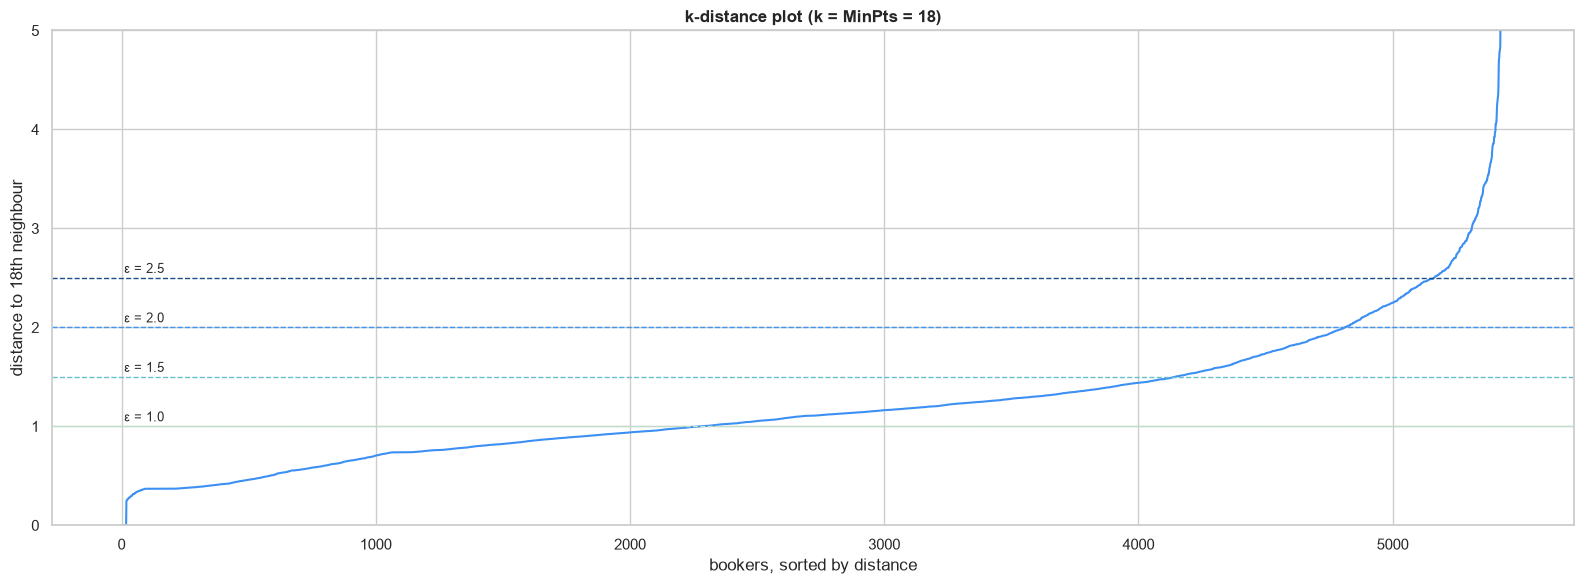

Distance to the 18th neighbour – 50 % / 90 % / 95 % of bookers below: [1.11 2.12 2.52]


In [20]:
MIN_PTS = 2 * X_scaled.shape[1]                                  # brief's rule: 2 × number of features = 18
nn = NearestNeighbors(n_neighbors=MIN_PTS).fit(X_scaled)
k_dist = np.sort(nn.kneighbors(X_scaled)[0][:, -1])              # distance to the 18th neighbour, sorted

fig, ax = plt.subplots(figsize=(16, 6))
ax.plot(k_dist, color=PALETTE[0])
for eps, shade in zip([1.0, 1.5, 2.0, 2.5], theme_shades(4)):    # candidate ε values tested in 6.2
    ax.axhline(eps, color=shade, ls="--", lw=1)
    ax.text(10, eps + 0.05, f"ε = {eps}", fontsize=9)
ax.set_title(f"k-distance plot (k = MinPts = {MIN_PTS})", fontweight="bold")
ax.set_xlabel("bookers, sorted by distance"); ax.set_ylabel(f"distance to {MIN_PTS}th neighbour")
ax.set_ylim(0, 5)                                                   # zoom in on the bend (a few extreme users go up to ~11)
plt.tight_layout(); plt.show()
print("Distance to the 18th neighbour – 50 % / 90 % / 95 % of bookers below:", np.quantile(k_dist, [0.5, 0.9, 0.95]).round(2))

### 6.2 Testing ε around the elbow
For each candidate ε: number of clusters, share of noise, size of the largest cluster, and the silhouette score of the clustered users (noise left out, as it belongs to no cluster).

In [21]:
grid = []
for eps in [1.0, 1.2, 1.5, 1.8, 2.0, 2.5]:
    labels = DBSCAN(eps=eps, min_samples=MIN_PTS).fit_predict(X_scaled)   # −1 = noise
    in_cluster = labels != -1
    n_clusters = len(set(labels[in_cluster]))
    grid.append({"eps": eps, "clusters": n_clusters,
                 "noise %": round((~in_cluster).mean() * 100, 1),
                 "largest cluster %": round(pd.Series(labels[in_cluster]).value_counts().max() / len(labels) * 100, 1),
                 "silhouette (without noise)": round(silhouette_score(X_scaled[in_cluster], labels[in_cluster]), 3) if n_clusters > 1 else None})
display(pd.DataFrame(grid).set_index("eps"))

,clusters,noise %,largest cluster %,silhouette (without noise)
eps,,,,
1.0,11,41.3,44.2,0.096
1.2,8,25.0,58.5,0.215
1.5,7,13.0,65.0,0.229
1.8,3,7.8,79.0,0.191
2.0,4,5.2,80.5,0.174
2.5,1,1.7,98.3,NaN


**Reading the grid** *(numbers from my run)*:
- **Small ε (1.0–1.2):** many tiny clusters and 25–41 % noise – too strict, a quarter or more of all bookers would be "outliers".
- **Large ε (≥ 2.0):** almost everyone falls into one big cluster – DBSCAN no longer separates anything.
- **Choice: ε = 1.5** – where the k-distance curve starts to bend: the best silhouette of the grid (0.23) with a moderate 13 % noise. At the sharpest bend (≈ 2.5) DBSCAN puts 98 % of bookers into one cluster – technically valid, but it separates nothing. Even here, **one dense cluster holds about two thirds of all bookers** – the same message as the low K-Means scores: TravelTide's customers form a continuum, not separate islands.

### 6.3 What DBSCAN finds at ε = 1.5

In [22]:
EPS = 1.5
bookers["dbscan"] = DBSCAN(eps=EPS, min_samples=MIN_PTS).fit_predict(X_scaled)

# One row per DBSCAN cluster: size, its strongest feature (standardized average) and the rule segment it mostly contains
z = pd.DataFrame(X_scaled, columns=KM_FEATURES, index=bookers.index)
summary = []
for label, members in bookers.groupby("dbscan"):
    z_mean = z.loc[members.index].mean()
    top_segment = members["segment"].value_counts(normalize=True)
    summary.append({"DBSCAN cluster": "noise (outliers)" if label == -1 else label, "users": len(members),
                    "stands out on": f"{z_mean.idxmax()} (+{z_mean.max():.1f})" if z_mean.max() > 0.5 else "nothing (average users)",
                    "main rule segment": f"{top_segment.index[0]} ({top_segment.iloc[0]:.0%})"})
display(pd.DataFrame(summary).set_index("DBSCAN cluster"))

# Do DBSCAN's outliers match the extreme users from 5.5?
noise = bookers["dbscan"] == -1
print(f"Noise: {noise.sum():,} bookers ({noise.mean():.0%}) | of the {extreme.sum()} extreme users (5 × IQR, 5.5), "
      f"{noise[extreme].mean():.0%} are labelled noise")
print(f"Agreement with K-Means (adjusted Rand index): {adjusted_rand_score(bookers['cluster'], bookers['dbscan']):.2f}")
print(bookers.loc[noise, "segment"].value_counts(normalize=True).head(3).round(2))   # who the noise users are

,users,stands out on,main rule segment
DBSCAN cluster,,,
noise (outliers),710,party_size (+1.0),Couples & Friends (33%)
0,3537,nothing (average users),All-rounders (35%)
1,218,cancel_rate (+2.3),All-rounders (43%)
2,628,max_visits_same_city (+2.1),Favourite-City Returners (81%)
3,38,cancel_rate (+4.5),All-rounders (79%)
4,254,hotel_only_share (+2.8),Hotel Stayers (68%)
5,39,hotel_only_share (+2.8),Hotel Stayers (95%)
6,18,max_visits_same_city (+4.6),Favourite-City Returners (100%)


Noise: 710 bookers (13%) | of the 115 extreme users (5 × IQR, 5.5), 97% are labelled noise
Agreement with K-Means (adjusted Rand index): 0.28
segment
Couples & Friends    0.33
Family Crew          0.20
Hotel Stayers        0.17
Name: proportion, dtype: float64


**What DBSCAN confirms** *(numbers from my run)*:
- **One big dense cluster (~3,500 bookers)** of "average" users – no stand-out habit. DBSCAN cannot split them; K-Means can only cut them into slices.
- **The clearly separate groups are the same ones the habit test (3.1) and K-Means found:** *Favourite-City Returners* (81 % of their cluster), *Hotel Stayers* (68 % and 95 % of two hotel-only clusters) and the *cancellers* (5.6).
- **Noise = the extremes:** 13 % of bookers – just over half are group travellers (Couples & Friends 33 %, Family Crew 20 %), more than twice their share among all bookers – and 97 % of the 115 extreme users from 5.5 are labelled noise. Both methods agree on who the outliers are.

### 6.4 K-Means vs. DBSCAN vs. rules – which does the better job?

| Method | Groups | Users without a group | Silhouette | Role in this project |
|---|---|---|---|---|
| **Rules + perk scores** | 8 segments + All-rounders | 0 | – | **final perk assignment** – every customer, easy to explain |
| K-Means (k = 8) | 8 | 0 | 0.18 | check: finds 4 of 7 booker segments on its own |
| DBSCAN (ε = 1.5, MinPts = 18) | 7 + noise | 13 % | 0.23 *(noise left out)* | check: confirms the truly separate groups, flags outliers |

DBSCAN's higher silhouette is not a better segmentation: it leaves 13 % of customers unassigned and puts two thirds into one cluster. **For Elena's goal – one perk for every customer – neither algorithm alone is enough.** Both serve as evidence: the groups they find on their own (Favourite-City Returners, Hotel Stayers, group travellers, cancellers) are the ones the rules and the habit test also support.

## 7 – PCA: do we need all 9 features?
**PCA** (principal component analysis) turns the 9 features into new axes – *components* – ordered by how much of the differences between users they capture. If 2–3 components captured most of it, the data could be simplified and shown in one picture. Same input as K-Means: the 9 standardized features of the bookers.

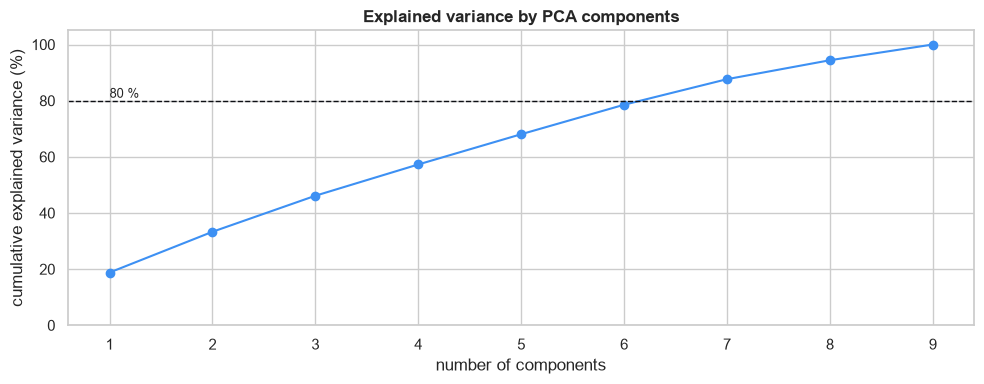

First 2 components: 33% of the variance | components needed for 80 %: 7 of 9
K-Means on 7 components: silhouette 0.185 (all 9 features: 0.177) | agreement with 5.2 (adjusted Rand index): 0.47


In [23]:
pca_full = PCA().fit(X_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)       # share of the differences explained by the first n components
n_80 = int(np.argmax(cum_var >= 0.8) + 1)                     # components needed for 80 %

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(range(1, len(cum_var) + 1), cum_var * 100, marker="o", color=PALETTE[0])
ax.axhline(80, color=PALETTE[4], ls="--", lw=1); ax.text(1, 81, "80 %", fontsize=9)
ax.set_xlabel("number of components"); ax.set_ylabel("cumulative explained variance (%)")
ax.set_title("Explained variance by PCA components", fontweight="bold"); ax.set_ylim(0, 105)
plt.tight_layout(); plt.show()
print(f"First 2 components: {cum_var[1]:.0%} of the variance | components needed for 80 %: {n_80} of {len(cum_var)}")

# Brief's call to action: cluster again on the reduced data and compare with K-Means on all features (5.2)
X_pca = PCA(n_components=n_80).fit_transform(X_scaled)
labels_pca = KMeans(n_clusters=K, n_init=10, random_state=42).fit_predict(X_pca)
print(f"K-Means on {n_80} components: silhouette {silhouette_score(X_pca, labels_pca):.3f} "
      f"(all 9 features: {silhouette_score(X_scaled, bookers['cluster']):.3f}) | "
      f"agreement with 5.2 (adjusted Rand index): {adjusted_rand_score(bookers['cluster'], labels_pca):.2f}")

**Result** *(numbers from my run)*: the first two components explain only about a third of the differences, and 7 of 9 components are needed for 80 % – there is no small set of "super features". This matches the correlation check in Part 2: the features describe **different** behaviors. Clustering on the 7 components barely changes the silhouette and gives partly different clusters, while the clusters become harder to name (components are mixes of features). → **The segmentation stays on the original 9 features**; PCA is used for the picture below.

### 7.1 All bookers on one map
The first two components as x and y, coloured three ways: by **rule segment**, by **K-Means** cluster and by **DBSCAN** cluster. Overlapping colours show again that behavior is a continuum; the groups that stand apart (hotel-only stays, repeat cities) are visible in all three panels.

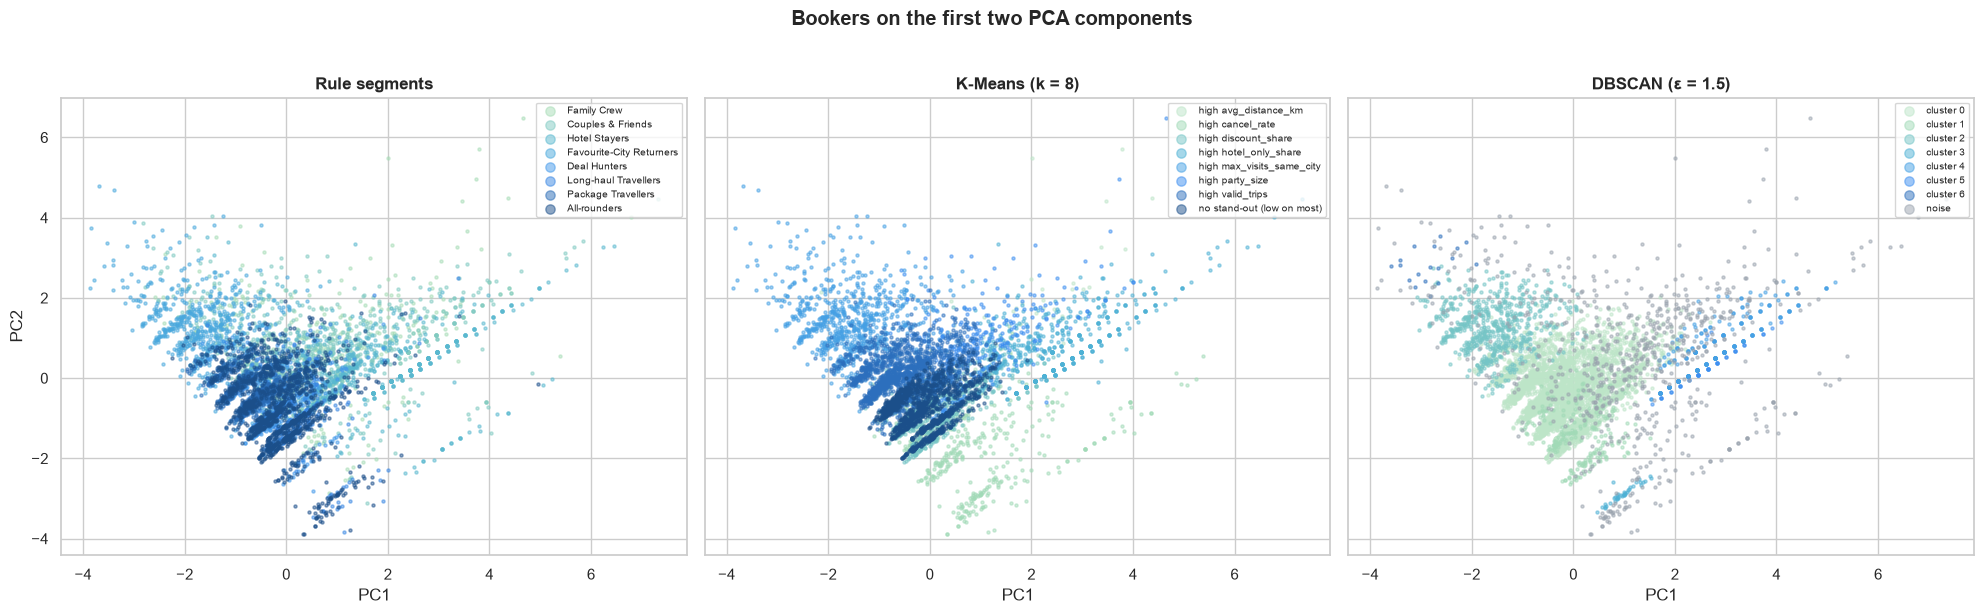

In [24]:
pc = PCA(n_components=2).fit_transform(X_scaled)
fig, axes = plt.subplots(1, 3, figsize=(20, 6), sharex=True, sharey=True)
panels = [("Rule segments", bookers["segment"], {s: SEGMENT_COLORS[s] for s in SEGMENT_ORDER}),
          ("K-Means (k = 8)", bookers["cluster"].map(names), None),
          ("DBSCAN (ε = 1.5)", bookers["dbscan"].map(lambda c: "noise" if c == -1 else f"cluster {c}"), None)]
for ax, (title, groups, colors) in zip(axes, panels):
    order = [g for g in (colors or {}) if g in set(groups)] or sorted(groups.unique())
    shades = colors or dict(zip(order, theme_shades(len(order))))
    if "noise" in shades: shades["noise"] = "#9AA3AE"                  # outliers in grey
    for g in order:
        m = (groups == g).values
        ax.scatter(pc[m, 0], pc[m, 1], s=5, alpha=0.5, color=shades[g], label=g)
    ax.set_title(title, fontweight="bold"); ax.set_xlabel("PC1")
    ax.legend(fontsize=7, markerscale=3, loc="upper right")
axes[0].set_ylabel("PC2")
fig.suptitle("Bookers on the first two PCA components", fontweight="bold", y=1.02)
plt.tight_layout(); plt.show()

*All three methods show the same picture: customers form one continuum with two arms that clearly stand apart – repeat-city travellers and hotel stayers – while everyone else overlaps. That’s why the perks are assigned with rules and perk scores, with the algorithms as a check.*

## 8 – Personas: one typical customer per segment
For the presentation, each segment gets a real customer from the data: the member **closest to the segment's median** on the behavioral features (standardized). Users under 18 are skipped, because many of their birthdates are placeholders (Part 1, 3.7). Dreamers have no trips, so they are matched on age and browsing behavior instead.

In [25]:
TRIP_FEATURES = ["valid_trips", "party_size", "avg_nights", "hotel_only_share", "combo_share",
                 "avg_distance_km", "discount_share", "max_visits_same_city", "cancel_rate"]
DREAMER_FEATURES = ["age", "avg_session_min", "avg_page_clicks", "cancelled_trips"]

def typical_member(members, features):
    """The member closest to the segment's median (all features standardized, so each counts equally)."""
    z = members[features].fillna(members[features].median()) # fill missing values with the median (neutral) for this segment
    z = (z - z.mean()) / z.std().replace(0, 1)
    return (z - z.median()).abs().sum(axis=1).idxmin()

adults = users[users["age"] >= 18]
persona_ids = {seg: typical_member(adults[adults["segment"] == seg],
                                   DREAMER_FEATURES if seg == "Dreamers" else TRIP_FEATURES)
               for seg in SEGMENT_ORDER}

personas = users.loc[list(persona_ids.values()), ["segment", "age", "gender", "family_status", "home_city",
                                                  "valid_trips", "party_size", "avg_nights", "hotel_only_share",
                                                  "avg_distance_km", "discount_share", "max_visits_same_city",
                                                  "cancelled_trips", "perk", "pilot_perk"]]
display(personas.round(2))

,segment,age,gender,family_status,home_city,valid_trips,party_size,avg_nights,hotel_only_share,avg_distance_km,discount_share,max_visits_same_city,cancelled_trips,perk,pilot_perk
user_id,,,,,,,,,,,,,,,
567824,Dreamers,34,F,"Single, children",Ottawa,0,NaN,NaN,NaN,NaN,NaN,0,0,No cancellation fees,48-h Fare Lock
513096,Family Crew,29,F,"Married, children",Dallas,2,1.5,3.00,0.0,1968.0,0.00,1,0,Free hotel meal,Family fare
509324,Couples & Friends,48,F,"Married, no children",Winnipeg,3,1.5,3.00,0.0,1914.0,0.33,1,0,No cancellation fees,Bring-a-friend
508497,Hotel Stayers,36,F,"Single, no children",Calgary,2,1.0,6.00,0.5,1942.0,0.00,1,0,Free hotel meal,Welcome dinner on night 1
585745,Favourite-City Returners,46,F,"Married, no children",Lubbock,4,1.0,3.00,0.0,1848.0,0.25,2,0,1 night free hotel with flight,City stamp card
573493,Deal Hunters,47,F,"Married, children",El Paso,3,1.0,3.33,0.0,2082.0,0.67,1,0,Exclusive discounts,Price-drop guarantee
521379,Long-haul Travellers,55,F,"Married, no children",New York,2,1.0,3.50,0.0,3729.0,0.00,1,0,Extra-legroom seat,Free checked bag
542012,Package Travellers,45,F,"Single, no children",Nashville,3,1.0,3.33,0.0,1843.0,0.33,1,0,1 night free hotel with flight,Free airport transfer
547325,All-rounders,43,F,"Single, children",Oklahoma City,2,1.0,3.50,0.0,1778.0,0.00,1,0,Free checked bag,NaN


**How to use them:** one persona per segment slide or in the segment overview – e.g. *"Meet user 123456: 42, married, two trips a year, always hotel-only, six nights → free hotel meal"*. Real numbers from the data make the segments tangible for Elena, and they can be checked in `user_perks.csv`.

## 9 – Save

In [26]:
users["kmeans_cluster"] = bookers["cluster"]          # empty for Dreamers (not clustered)
users["dbscan_cluster"] = bookers["dbscan"]           # −1 = noise (outlier); empty for Dreamers
users.reset_index().to_csv(DATA_DIR / "users_segments.csv", index=False)
print("Saved:", (DATA_DIR / "users_segments.csv").resolve(), "|", users.shape)

# Deliverable for Elena: one row per customer with their perk (brief: "CSV file with users assigned to the perks")
user_perks = users.reset_index()[["user_id", "segment", "perk", "perk_source", "pilot_perk"]] #select only the columns needed for Elena's brief
assert user_perks["perk"].notna().all() and user_perks["user_id"].is_unique # sanity check: every user has a perk and no duplicates
user_perks.to_csv(DATA_DIR / "user_perks.csv", index=False)
print("Saved:", (DATA_DIR / "user_perks.csv").resolve(), "|", user_perks.shape)
display(user_perks.head())

Saved: C:\Users\jackl\OneDrive\Attachments\Desktop\Masterschool\Mastery Project\TravelTide\data\users_segments.csv | (5998, 42)
Saved: C:\Users\jackl\OneDrive\Attachments\Desktop\Masterschool\Mastery Project\TravelTide\data\user_perks.csv | (5998, 5)


,user_id,segment,perk,perk_source,pilot_perk
0,23557,Couples & Friends,No cancellation fees,segment rule,Bring-a-friend
1,94883,Couples & Friends,No cancellation fees,segment rule,Bring-a-friend
2,101486,Family Crew,Free hotel meal,segment rule,Family fare
3,101961,Package Travellers,1 night free hotel with flight,segment rule,Free airport transfer
4,106907,Dreamers,No cancellation fees,segment rule,48-h Fare Lock
